# Real Data Inference with NPE

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pickle
import h5py

from omegaconf import OmegaConf
from pathlib import Path

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.inference.posteriors import DirectPosterior

import sys

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from priors import generate_posterior_prior_from_config, generate_fret_prior_from_config
from utils import eval_free_energy_from_config, eval_force_from_config

/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration

In [2]:
# Trained model path
cfg_path = "/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/exp_4/22-36-25/"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Experimental data
DATA_ROOT = Path("/home/dingeldein/Desktop/fret_sbi/data_ben_schuler/Sturzenegger_transition_path_data")
CONDITION_INDEX = 8 # ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi (base condition)

# Observation settings
n_observations = 50

# Posterior sampling
num_posterior_samples = 10000
posterior_batch_size = 1000

# MAP estimation
map_num_iter = 1000
map_learning_rate = 0.01
map_num_init_samples = 10

## Load Model, Prior, and Config

In [3]:
data_cfg_path = cfg_path + "data_config.yaml"

prior_posterior = generate_posterior_prior_from_config(data_cfg_path, device=device)
eval_force = eval_force_from_config(data_cfg_path)
eval_free_energy = eval_free_energy_from_config(data_cfg_path)
data_cfg = OmegaConf.load(data_cfg_path)

num_knots = data_cfg.prior.num_knots
theta_dim = num_knots + 2  # [logD, g_0..g_{n-1}, R0]

# Extract simulator timing from config
sim_bin_width_ms = data_cfg.simulator.time_step * data_cfg.simulator.saving_frequency
L_max_bins = data_cfg.simulator.binding.L_max_bins

print(f"Model expects: (n_obs, {L_max_bins}, 3) at {sim_bin_width_ms} ms bin width")
print(f"Posterior dimensionality: {theta_dim} = 1 (logD) + {num_knots} (knots) + 1 (R0)")

# Load density estimator
try:
    with open(cfg_path + "npe_set_estimator.pkl", "rb") as f:
        density_estimator = pickle.load(f)
except FileNotFoundError:
    with open(cfg_path + "last_npe_set_estimator.pkl", "rb") as f:
        density_estimator = pickle.load(f)

density_estimator = density_estimator.to(device)
density_estimator.eval()
print("Density estimator loaded.")

Model expects: (n_obs, 4300, 3) at 0.005 ms bin width
Posterior dimensionality: 9 = 1 (logD) + 7 (knots) + 1 (R0)
Density estimator loaded.


## Data Loading and Transformation

Load photon-by-photon HDF5 data and transform into the tensor format the NPE model expects:
- Bin photons at the simulator's native resolution (`sim_bin_width_ms`)
- Pad/truncate to `L_max_bins`
- Add binary mask channel (1 = valid, 0 = padding)

In [4]:
ACCEPTOR_ID = 1
DONOR_ID = 2


def get_trajectory_data(traj_file):
    """Load a single trajectory from an HDF5 file."""
    with h5py.File(traj_file, "r") as f:
        detector = f["Detectors"][:]
        interphoton_ds = f["InterPhotonTimes"]
        interphoton_times = interphoton_ds[:]
        macro_time_unit_ps = interphoton_ds.attrs["MacroTimeUnitInPicoSeconds"]
    return interphoton_times, macro_time_unit_ps, detector


def photons_to_model_input(interphoton_times, macro_time_unit_ps, detector,
                           sim_bin_width_ms, L_max_bins):
    """Bin photon arrivals at simulator resolution and format as model input.

    Returns
    -------
    tensor : torch.Tensor, shape (L_max_bins, 3)
        Channels: [donor_counts, acceptor_counts, mask].
    n_valid_bins : int
        Number of bins with actual data (before padding).
    """
    bin_width_ps = np.int64(sim_bin_width_ms * 1e9)  # ms -> ps
    macro_time_unit_ps = np.int64(macro_time_unit_ps)

    interphoton_times_ps = interphoton_times.astype(np.int64) * macro_time_unit_ps
    photon_times_ps = np.cumsum(interphoton_times_ps, dtype=np.int64)

    total_time_ps = photon_times_ps[-1]
    n_bins = max(1, int(np.ceil(total_time_ps / bin_width_ps)))

    # Truncate or keep as-is
    n_valid = min(n_bins, L_max_bins)
    bin_edges = np.linspace(0, n_valid * bin_width_ps, n_valid + 1)

    donor_counts, _ = np.histogram(photon_times_ps[detector == DONOR_ID], bins=bin_edges)
    acceptor_counts, _ = np.histogram(photon_times_ps[detector == ACCEPTOR_ID], bins=bin_edges)

    # Build (L_max_bins, 3) tensor: [donor, acceptor, mask]
    out = torch.zeros(L_max_bins, 3, dtype=torch.float32)
    out[:n_valid, 0] = torch.from_numpy(donor_counts.astype(np.float32))
    out[:n_valid, 1] = torch.from_numpy(acceptor_counts.astype(np.float32))
    out[:n_valid, 2] = 1.0  # mask

    return out, n_valid

In [5]:
# List available conditions
conditions = sorted([d.name for d in DATA_ROOT.iterdir() if d.is_dir()])
for i, cond in enumerate(conditions):
    n_files = len(list((DATA_ROOT / cond).glob("*.h5")))
    print(f"  [{i:2d}] {cond}  ({n_files} trajectories)")

condition_name = conditions[CONDITION_INDEX]
condition_dir = DATA_ROOT / condition_name
traj_files = sorted([str(f) for f in condition_dir.glob("*.h5")])
print(f"\nSelected: {condition_name} ({len(traj_files)} trajectories)")

  [ 0] ACTR-avi-Alexa488_NCBD-CF660R_50mMNaPi  (394 trajectories)
  [ 1] ACTR-avi-Cy3B_NCBD-CF660R_20mMNaPi_10mMNaCl  (174 trajectories)
  [ 2] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi  (591 trajectories)
  [ 3] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_100mMNaCl  (236 trajectories)
  [ 4] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_14%glycerol  (288 trajectories)
  [ 5] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_175mMNaCl  (338 trajectories)
  [ 6] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_300mMNaCl  (182 trajectories)
  [ 7] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_32%glycerol  (277 trajectories)
  [ 8] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_45%glycerol  (364 trajectories)
  [ 9] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_50mMNaCl  (78 trajectories)
  [10] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_800mMNaCl  (179 trajectories)
  [11] NCBD-avi-Cy3B_ACTR-CF660R_50mMNaPi  (81 trajectories)

Selected: ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_45%glycerol (364 trajectories)


In [6]:
# Load and transform all trajectories
all_tensors = []
all_valid_bins = []

for traj_file in traj_files:
    ipt, mtu, det = get_trajectory_data(traj_file)
    tensor, n_valid = photons_to_model_input(ipt, mtu, det, sim_bin_width_ms, L_max_bins)
    if n_valid > 0:
        all_tensors.append(tensor)
        all_valid_bins.append(n_valid)

print(f"Loaded {len(all_tensors)} valid trajectories (skipped {len(traj_files) - len(all_tensors)})")
valid_bins_arr = np.array(all_valid_bins)
print(f"Valid bins: min={valid_bins_arr.min()}, median={np.median(valid_bins_arr):.0f}, "
      f"max={valid_bins_arr.max()}, L_max_bins={L_max_bins}")
print(f"Duration range: {valid_bins_arr.min() * sim_bin_width_ms:.2f} - "
      f"{valid_bins_arr.max() * sim_bin_width_ms:.2f} ms")

# Select n_observations trajectories
if len(all_tensors) < n_observations:
    print(f"WARNING: only {len(all_tensors)} trajectories available, using all")
    selected_idx = list(range(len(all_tensors)))
else:
    rng = np.random.default_rng(42)
    selected_idx = rng.choice(len(all_tensors), size=n_observations, replace=False)
    selected_idx.sort()

obs_tensors = [all_tensors[i] for i in selected_idx]
obs_valid = [all_valid_bins[i] for i in selected_idx]
observation = torch.stack(obs_tensors).unsqueeze(0)  # (1, n_obs, L_max_bins, 3)
print(f"\nObservation tensor shape: {observation.shape}")
print(f"Selected {len(selected_idx)} trajectories")

Loaded 364 valid trajectories (skipped 0)
Valid bins: min=1431, median=4300, max=4300, L_max_bins=4300
Duration range: 7.16 - 21.50 ms

Observation tensor shape: torch.Size([1, 50, 4300, 3])
Selected 50 trajectories


## Visualize Transformed Observations

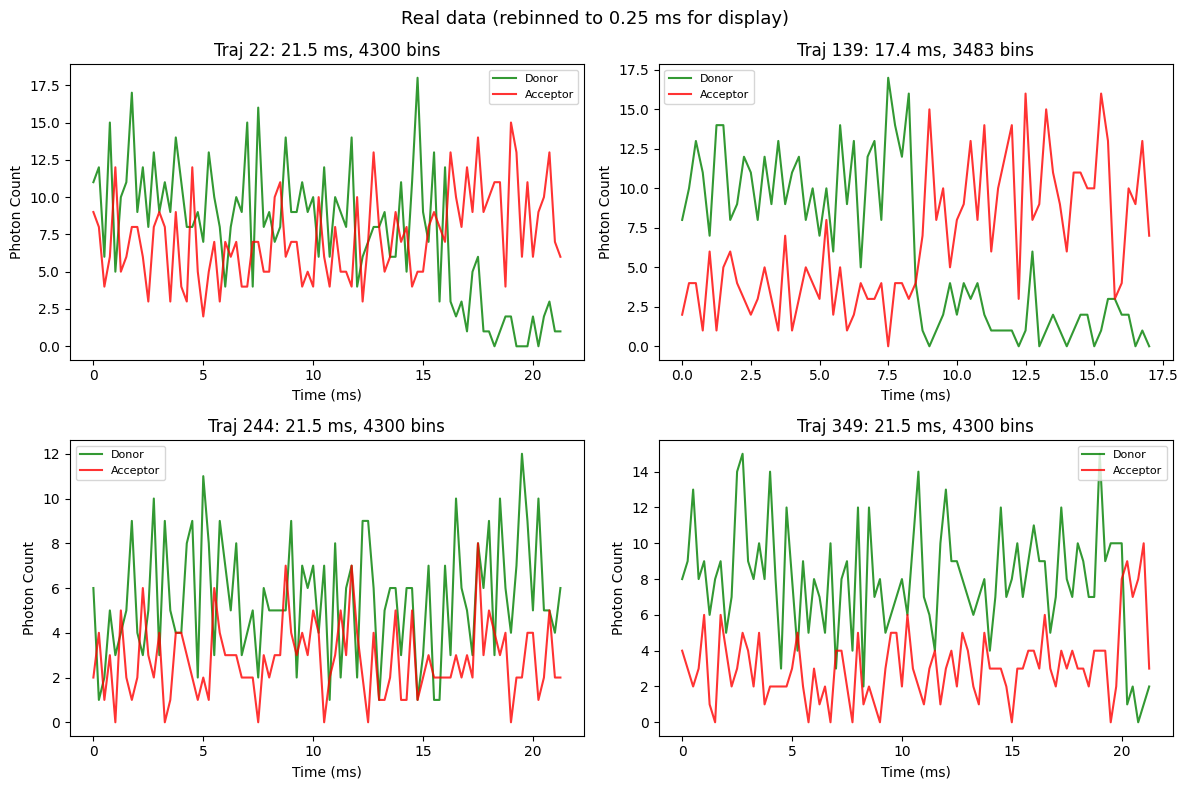

In [7]:
VIS_BIN_WIDTH_MS = 0.25  # coarser bins for visualization
sim_bins_per_vis_bin = max(1, int(round(VIS_BIN_WIDTH_MS / sim_bin_width_ms)))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
show_idx = np.linspace(0, len(obs_tensors) - 1, 4, dtype=int)

for ax, idx in zip(axes.flat, show_idx):
    trace = obs_tensors[idx]
    n_valid = obs_valid[idx]

    # Rebin valid region into coarser visualization bins
    n_vis = n_valid // sim_bins_per_vis_bin
    if n_vis > 0:
        donor = trace[:n_vis * sim_bins_per_vis_bin, 0].reshape(n_vis, sim_bins_per_vis_bin).sum(dim=1).numpy()
        acceptor = trace[:n_vis * sim_bins_per_vis_bin, 1].reshape(n_vis, sim_bins_per_vis_bin).sum(dim=1).numpy()
        t = np.arange(n_vis) * VIS_BIN_WIDTH_MS
        ax.plot(t, donor, color="green", alpha=0.8, label="Donor")
        ax.plot(t, acceptor, color="red", alpha=0.8, label="Acceptor")

    dur_ms = n_valid * sim_bin_width_ms
    ax.set_title(f"Traj {selected_idx[idx]}: {dur_ms:.1f} ms, {n_valid} bins")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Photon Count")
    ax.legend(fontsize=8)

plt.suptitle(f"Real data (rebinned to {VIS_BIN_WIDTH_MS} ms for display)", fontsize=13)
plt.tight_layout()

## Posterior Inference

In [8]:
posterior = DirectPosterior(density_estimator, prior=prior_posterior)
obs = observation.to(device)

samples = posterior.sample(
    (num_posterior_samples,),
    x=obs,
    max_sampling_batch_size=posterior_batch_size,
).cpu()

print(f"Samples shape: {samples.shape}  (expected: [{num_posterior_samples}, {theta_dim}])")

# MAP estimate
posterior.set_default_x(obs)
map_estimate = posterior.map(
    num_iter=map_num_iter,
    num_init_samples=map_num_init_samples,
    learning_rate=map_learning_rate,
    show_progress_bars=True,
    force_update=True,
)
print(f"MAP estimate: {map_estimate[0].cpu().numpy().round(3)}")

10097it [00:01, 6988.59it/s]                          


Samples shape: torch.Size([10000, 9])  (expected: [10000, 9])


100%|██████████| 10/10 [00:00<00:00, 164.54it/s]


 Optimizing MAP estimate. Iterations: 973 / 1000. Performance in iteration 970: -3.46 (= unnormalized log-prob). Press Ctrl-C to interrupt.Optimization was interrupted after 973 iterations. 
MAP estimate: [ 0.386 -0.598 -4.427  3.369 -2.891 -0.485 -1.342  4.951  5.58 ]


## Results

/tmp/ipykernel_3338746/587263198.py:12: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


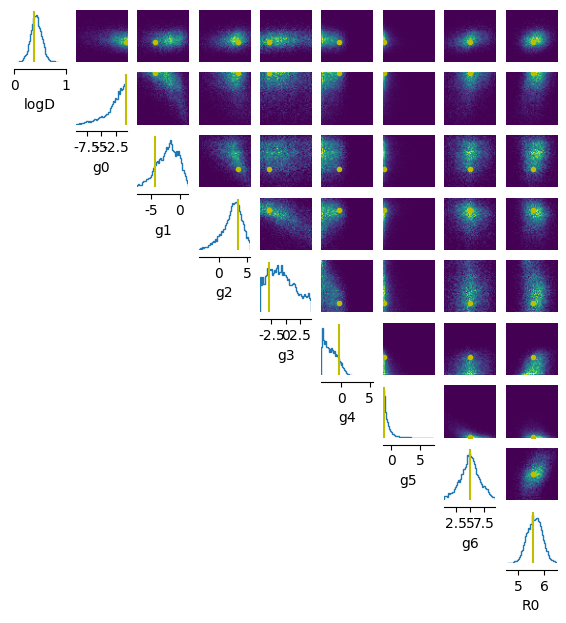

In [9]:
param_labels = ["logD"] + [f"g{i}" for i in range(num_knots)] + ["R0"]

scale = data_cfg.prior.scale
center = list(data_cfg.prior.center) if data_cfg.prior.center is not None else [0.0] * num_knots

limits = (
    [list(data_cfg.prior.logD_lims)]
    + [[c - scale, c + scale] for c in center]
    + [list(data_cfg.prior.R0_lims)]
)

_ = analysis.pairplot(
    samples,
    figsize=(7, 7),
    points=[map_estimate[0].cpu()],
    points_offdiag={"markersize": 6},
    points_colors=["y"],
    limits=limits,
    labels=param_labels,
)

### Free Energy Landscape

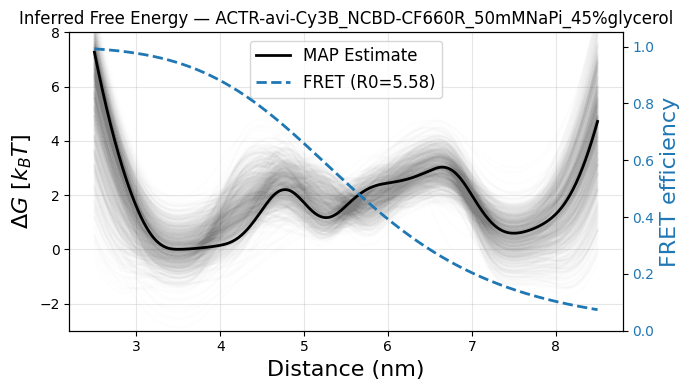

In [10]:
knot_spacing = (data_cfg.simulator.x_max - data_cfg.simulator.x_min) / (num_knots - 1)
x_plot_margin = 0.6 * data_cfg.simulator.num_boundary_knots * knot_spacing
x_eval = np.linspace(data_cfg.simulator.x_min - x_plot_margin,
                     data_cfg.simulator.x_max + x_plot_margin, 500)

fig, ax1 = plt.subplots(figsize=(7, 4))

# MAP free energy (reference for vertical alignment)
x, y_map = eval_free_energy(params=map_estimate[0].cpu(), x_eval=x_eval)
y_map_shifted = y_map - y_map.min()

# Posterior free energy samples (aligned to MAP)
for i in range(1000):
    x, y = eval_free_energy(params=samples[i], x_eval=x_eval)
    offset = np.mean(y_map_shifted - y)
    ax1.plot(x, y + offset, color="gray", alpha=0.01)

# MAP
ax1.plot(x, y_map_shifted, color="black", lw=2, label="MAP Estimate")

ax1.set_xlabel("Distance (nm)", fontsize=16)
ax1.set_ylabel(r"$\Delta G\ [k_BT]$", fontsize=16)
ax1.set_ylim(-3, 8)
ax1.grid(alpha=0.3)

# FRET efficiency on secondary axis (use MAP R0)
ax2 = ax1.twinx()
R0_map = float(map_estimate[0, -1].cpu())
r = np.clip(x_eval, 1e-9, None)
E = 1.0 / (1.0 + (r / R0_map) ** 6)
ax2.plot(x_eval, E, color="tab:blue", linestyle="--", linewidth=2, label=f"FRET (R0={R0_map:.2f})")
ax2.set_ylabel("FRET efficiency", color="tab:blue", fontsize=16)
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis="y", labelcolor="tab:blue")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=12, loc="best")
ax1.set_title(f"Inferred Free Energy — {condition_name}", fontsize=12)
plt.tight_layout()

### Diffusion Coefficient

In [ ]:
logD_samples = samples[:, 0].numpy()
D_samples = 10 ** logD_samples  # nm^2/ms

D_median = np.median(D_samples)
D_lo, D_hi = np.percentile(D_samples, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# logD posterior
axes[0].hist(logD_samples, bins=50, edgecolor="black", alpha=0.7, color="steelblue")
axes[0].axvline(float(map_estimate[0, 0].cpu()), color="orange", ls="--", lw=2, label="MAP")
axes[0].set_xlabel("logD", fontsize=14)
axes[0].set_ylabel("Count", fontsize=14)
axes[0].set_title("Posterior: logD")
axes[0].legend()

# D posterior
axes[1].hist(D_samples, bins=50, edgecolor="black", alpha=0.7, color="teal")
axes[1].axvline(D_median, color="black", ls="--", lw=1.5, label=f"Median = {D_median:.3f}")
axes[1].axvspan(D_lo, D_hi, alpha=0.15, color="gray", label=f"95% CI = [{D_lo:.3f}, {D_hi:.3f}]")
axes[1].set_xlabel(r"$D$ (nm$^2$/ms)", fontsize=14)
axes[1].set_ylabel("Count", fontsize=14)
axes[1].set_title("Posterior: Diffusion Coefficient")
axes[1].legend(fontsize=10)

plt.tight_layout()

print(f"Diffusion coefficient D (nm^2/ms):")
print(f"  Median: {D_median:.4f}")
print(f"  95% CI: [{D_lo:.4f}, {D_hi:.4f}]")
print(f"  MAP:    {10**float(map_estimate[0, 0].cpu()):.4f}")

In [ ]:
R0_samples = samples[:, -1].numpy()  # R0 is the last parameter, no log transform

R0_median = np.median(R0_samples)
R0_lo, R0_hi = np.percentile(R0_samples, [2.5, 97.5])
R0_map = float(map_estimate[0, -1].cpu())

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(R0_samples, bins=50, edgecolor="black", alpha=0.7, color="mediumpurple")
ax.axvline(R0_map, color="orange", ls="--", lw=2, label=f"MAP = {R0_map:.3f}")
ax.axvline(R0_median, color="black", ls="--", lw=1.5, label=f"Median = {R0_median:.3f}")
ax.axvspan(R0_lo, R0_hi, alpha=0.15, color="gray", label=f"95% CI = [{R0_lo:.3f}, {R0_hi:.3f}]")

ax.set_xlabel(r"$R_0$ (nm)", fontsize=14)
ax.set_ylabel("Count", fontsize=14)
ax.set_title("Posterior: $R_0$")
ax.legend(fontsize=10)

plt.tight_layout()

print("R0 (nm):")
print(f"  Median: {R0_median:.4f}")
print(f"  95% CI: [{R0_lo:.4f}, {R0_hi:.4f}]")
print(f"  MAP:    {R0_map:.4f}")


## Posterior Predictive Checks

Simulate trajectories from the MAP estimate (with nuisance photophysics parameters sampled from their priors) and compare summary statistics against the real observations.

In [ ]:
from simulator import binding_simulator_wrapper_from_config

simulate = binding_simulator_wrapper_from_config(data_cfg_path)
fret_prior = generate_fret_prior_from_config(data_cfg_path, device="cpu")
map_7 = map_estimate[0].cpu()
num_ppc_sim = 1000

sim_tensors = []
sim_valid = []
max_retries = 10

while len(sim_tensors) < num_ppc_sim:
    nuisance = fret_prior.sample((1,)).squeeze()
    # Overwrite inferred params with MAP values
    params_16 = nuisance.clone()
    params_16[0] = map_7[0]                        # logD
    params_16[1:num_knots + 1] = map_7[1:-1]       # g0..g4
    params_16[num_knots + 1] = map_7[-1]            # R0

    result = simulate(params_16)
    if result is not None:
        trace, length = result
        # Add mask channel: (L_max_bins, 2) -> (L_max_bins, 3)
        tensor_3ch = torch.zeros(L_max_bins, 3, dtype=torch.float32)
        if isinstance(trace, torch.Tensor):
            tensor_3ch[:, :2] = trace
        else:
            tensor_3ch[:, :2] = torch.from_numpy(trace)
        tensor_3ch[:length, 2] = 1.0
        sim_tensors.append(tensor_3ch)
        sim_valid.append(length)
        print(f"\r  Simulated {len(sim_tensors)}/{num_ppc_sim} trajectories", end="")

print(f"\nDone. Simulated {len(sim_tensors)} trajectories.")
sim_valid_arr = np.array(sim_valid)
print(f"Valid bins: min={sim_valid_arr.min()}, median={np.median(sim_valid_arr):.0f}, max={sim_valid_arr.max()}")

In [ ]:
n_show = 4
sim_bins_per_vis_bin = max(1, int(round(VIS_BIN_WIDTH_MS / sim_bin_width_ms)))

fig, axes = plt.subplots(n_show, 2, figsize=(14, 3 * n_show), sharey=True)

# Pick trajectories spread across the set
show_idx_real = np.linspace(0, len(obs_tensors) - 1, n_show, dtype=int)
show_idx_sim = np.linspace(0, len(sim_tensors) - 1, n_show, dtype=int)

for row in range(n_show):
    # --- Left column: real ---
    ax = axes[row, 0]
    trace = obs_tensors[show_idx_real[row]]
    n_valid = obs_valid[show_idx_real[row]]
    n_vis = n_valid // sim_bins_per_vis_bin
    if n_vis > 0:
        donor = trace[:n_vis * sim_bins_per_vis_bin, 0].reshape(n_vis, sim_bins_per_vis_bin).sum(dim=1).numpy()
        acceptor = trace[:n_vis * sim_bins_per_vis_bin, 1].reshape(n_vis, sim_bins_per_vis_bin).sum(dim=1).numpy()
        t = np.arange(n_vis) * VIS_BIN_WIDTH_MS
        ax.plot(t, donor, color="green", alpha=0.8, label="Donor")
        ax.plot(t, acceptor, color="red", alpha=0.8, label="Acceptor")
    ax.set_title(f"Real #{show_idx_real[row]}  ({n_valid * sim_bin_width_ms:.1f} ms)", fontsize=10)
    ax.set_ylabel("Counts")
    if row == 0:
        ax.legend(fontsize=7)
    if row == n_show - 1:
        ax.set_xlabel("Time (ms)")

    # --- Right column: simulated ---
    ax = axes[row, 1]
    trace = sim_tensors[show_idx_sim[row]]
    n_valid = sim_valid[show_idx_sim[row]]
    n_vis = n_valid // sim_bins_per_vis_bin
    if n_vis > 0:
        donor = trace[:n_vis * sim_bins_per_vis_bin, 0].reshape(n_vis, sim_bins_per_vis_bin).sum(dim=1).numpy()
        acceptor = trace[:n_vis * sim_bins_per_vis_bin, 1].reshape(n_vis, sim_bins_per_vis_bin).sum(dim=1).numpy()
        t = np.arange(n_vis) * VIS_BIN_WIDTH_MS
        ax.plot(t, donor, color="green", alpha=0.8, label="Donor")
        ax.plot(t, acceptor, color="red", alpha=0.8, label="Acceptor")
    ax.set_title(f"Simulated #{show_idx_sim[row]}  ({n_valid * sim_bin_width_ms:.1f} ms)", fontsize=10)
    if row == 0:
        ax.legend(fontsize=7)
    if row == n_show - 1:
        ax.set_xlabel("Time (ms)")

axes[0, 0].set_title("Experimental\n" + axes[0, 0].get_title(), fontsize=10)
axes[0, 1].set_title("MAP Simulated\n" + axes[0, 1].get_title(), fontsize=10)
plt.suptitle(f"Trajectory Comparison (rebinned to {VIS_BIN_WIDTH_MS} ms)", fontsize=13, y=1.01)
plt.tight_layout()

In [ ]:
def compute_ppc_statistics(tensors, valid_bins_list, sim_bin_width_ms, rebin_factor=50):
    """Compute summary statistics for posterior predictive checks.

    Parameters
    ----------
    tensors : list of Tensor, each (L_max_bins, 3) with [donor, acceptor, mask]
    valid_bins_list : list of int, number of valid bins per trajectory
    sim_bin_width_ms : float, native bin width in ms
    rebin_factor : int, number of native bins per coarse bin

    Returns
    -------
    dict with keys: mean_photon_rate, mean_fret_E, pooled_E_rebinned,
                    donor_acceptor_corr, E_autocorr_lag1, count_var_mean_ratio,
                    max_delta_E
    """
    mean_photon_rate = []
    mean_fret_E = []
    pooled_E_rebinned = []
    donor_acceptor_corr = []
    E_autocorr_lag1 = []
    count_var_mean_ratio = []
    max_delta_E = []

    for tensor, n_valid in zip(tensors, valid_bins_list):
        donor = tensor[:n_valid, 0].numpy()
        acceptor = tensor[:n_valid, 1].numpy()
        total = donor + acceptor

        # --- Native resolution statistics ---
        duration_ms = n_valid * sim_bin_width_ms
        total_photons = total.sum()
        if total_photons > 0:
            mean_photon_rate.append(total_photons / duration_ms)
            mean_fret_E.append(acceptor.sum() / total_photons)
        else:
            continue

        # --- Rebinned statistics ---
        n_coarse = n_valid // rebin_factor
        if n_coarse < 2:
            # Not enough bins for rebinned statistics
            donor_acceptor_corr.append(np.nan)
            E_autocorr_lag1.append(np.nan)
            count_var_mean_ratio.append(np.nan)
            max_delta_E.append(np.nan)
            continue

        donor_rb = donor[:n_coarse * rebin_factor].reshape(n_coarse, rebin_factor).sum(axis=1)
        acc_rb = acceptor[:n_coarse * rebin_factor].reshape(n_coarse, rebin_factor).sum(axis=1)
        total_rb = donor_rb + acc_rb

        # Pooled E(t) — only bins with photons
        mask_nonzero = total_rb > 0
        if mask_nonzero.sum() > 0:
            E_bins = acc_rb[mask_nonzero] / total_rb[mask_nonzero]
            pooled_E_rebinned.extend(E_bins.tolist())

            # Max delta E
            max_delta_E.append(E_bins.max() - E_bins.min())
        else:
            max_delta_E.append(np.nan)

        # Donor-acceptor correlation
        if donor_rb.std() > 0 and acc_rb.std() > 0:
            corr = np.corrcoef(donor_rb, acc_rb)[0, 1]
            donor_acceptor_corr.append(corr)
        else:
            donor_acceptor_corr.append(np.nan)

        # E(t) autocorrelation at lag 1
        if mask_nonzero.sum() >= 3:
            E_ts = acc_rb / np.where(total_rb > 0, total_rb, 1.0)  # safe division
            E_valid = E_ts[mask_nonzero]
            if E_valid.std() > 0 and len(E_valid) >= 3:
                autocorr = np.corrcoef(E_valid[:-1], E_valid[1:])[0, 1]
                E_autocorr_lag1.append(autocorr)
            else:
                E_autocorr_lag1.append(np.nan)
        else:
            E_autocorr_lag1.append(np.nan)

        # Count variance/mean ratio
        if total_rb.mean() > 0:
            count_var_mean_ratio.append(total_rb.var() / total_rb.mean())
        else:
            count_var_mean_ratio.append(np.nan)

    return {
        "mean_photon_rate": np.array(mean_photon_rate),
        "mean_fret_E": np.array(mean_fret_E),
        "pooled_E_rebinned": np.array(pooled_E_rebinned),
        "donor_acceptor_corr": np.array(donor_acceptor_corr),
        "E_autocorr_lag1": np.array(E_autocorr_lag1),
        "count_var_mean_ratio": np.array(count_var_mean_ratio),
        "max_delta_E": np.array(max_delta_E),
    }

In [ ]:
rebin_factor = 50  # 50 × 0.005 ms = 0.25 ms coarse bins

stats_real = compute_ppc_statistics(obs_tensors, obs_valid, sim_bin_width_ms, rebin_factor)
stats_sim = compute_ppc_statistics(sim_tensors, sim_valid, sim_bin_width_ms, rebin_factor)

print("Real data statistics:")
for key in ["mean_photon_rate", "mean_fret_E", "donor_acceptor_corr", "E_autocorr_lag1", "count_var_mean_ratio", "max_delta_E"]:
    vals = stats_real[key]
    valid = vals[~np.isnan(vals)]
    print(f"  {key:25s}: median={np.median(valid):.3f}, IQR=[{np.percentile(valid, 25):.3f}, {np.percentile(valid, 75):.3f}] (n={len(valid)})")
print(f"  {'pooled_E_rebinned':25s}: {len(stats_real['pooled_E_rebinned'])} bins pooled")

In [ ]:
from scipy.stats import ks_2samp

per_traj_stats = [
    ("mean_photon_rate", "Mean Photon Rate (ph/ms)"),
    ("mean_fret_E", "Trajectory-Averaged FRET E"),
    ("donor_acceptor_corr", "Donor-Acceptor Correlation"),
    ("E_autocorr_lag1", "E(t) Autocorrelation (lag 1)"),
    ("count_var_mean_ratio", "Count Var/Mean Ratio"),
    ("max_delta_E", r"Max $\Delta E$"),
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flat

# Per-trajectory statistics (6 panels)
for ax, (key, label) in zip(axes, per_traj_stats):
    real_vals = stats_real[key]
    sim_vals = stats_sim[key]
    # Drop NaNs
    real_vals = real_vals[~np.isnan(real_vals)]
    sim_vals = sim_vals[~np.isnan(sim_vals)]

    if len(real_vals) > 0 and len(sim_vals) > 0:
        all_vals = np.concatenate([real_vals, sim_vals])
        bins = np.linspace(all_vals.min(), all_vals.max(), 20)
        ax.hist(real_vals, bins=bins, alpha=0.6, color="tab:blue", label="Real", density=True)
        ax.hist(sim_vals, bins=bins, alpha=0.6, color="tab:orange", label="Simulated", density=True)

        ks_stat, ks_pval = ks_2samp(real_vals, sim_vals)
        ax.set_title(f"{label}\nKS p={ks_pval:.3f}", fontsize=10)
    else:
        ax.set_title(f"{label}\n(insufficient data)", fontsize=10)

    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

# Pooled E(t) histogram (panel 7)
ax = axes[6]
real_E = stats_real["pooled_E_rebinned"]
sim_E = stats_sim["pooled_E_rebinned"]
if len(real_E) > 0 and len(sim_E) > 0:
    bins_E = np.linspace(0, 1, 40)
    ax.hist(real_E, bins=bins_E, alpha=0.6, color="tab:blue", label="Real", density=True)
    ax.hist(sim_E, bins=bins_E, alpha=0.6, color="tab:orange", label="Simulated", density=True)

    ks_stat, ks_pval = ks_2samp(real_E, sim_E)
    ax.set_title(f"Pooled E(t) Distribution\nKS p={ks_pval:.3f}", fontsize=10)
    ax.set_xlabel("FRET Efficiency")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

# Summary panel (panel 8)
ax = axes[7]
ax.axis("off")
summary_lines = ["PPC Summary", "=" * 30]
for key, label in per_traj_stats:
    real_vals = stats_real[key][~np.isnan(stats_real[key])]
    sim_vals = stats_sim[key][~np.isnan(stats_sim[key])]
    if len(real_vals) > 0 and len(sim_vals) > 0:
        _, p = ks_2samp(real_vals, sim_vals)
        summary_lines.append(f"{label[:25]:25s} p={p:.3f}")
if len(real_E) > 0 and len(sim_E) > 0:
    _, p = ks_2samp(real_E, sim_E)
    summary_lines.append(f"{'Pooled E(t)':25s} p={p:.3f}")
ax.text(0.05, 0.95, "\n".join(summary_lines), transform=ax.transAxes,
        fontsize=9, verticalalignment="top", fontfamily="monospace")

plt.suptitle(f"Posterior Predictive Checks: Real vs. MAP Simulated\n{condition_name}", fontsize=13)
plt.tight_layout()